# Landsat8 / RS：全部方法与并行模型实验

该 notebook 严格分开两种口径：完整测试集 likelihood-RD，以及 30 图真实码流与完整编解码时间。FMoW 暂不纳入。

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path('/data/huzhenghao/ml/h/并行优化')
CMP = ROOT / 'experiments' / 'comparison_all_methods'
TIME = ROOT / 'experiments' / 'landsat8_rs_summary'
rd = pd.read_csv(CMP / 'full_test_rd_all_methods.csv')
bd = pd.read_csv(CMP / 'bd_rate_hybrid_vs_methods.csv')
coverage = pd.read_csv(CMP / 'coverage.csv')
audit = pd.read_csv(CMP / 'monotonicity_audit.csv')
protocol = pd.read_csv(CMP / 'method_protocol_audit.csv')
real_time = pd.read_csv(TIME / 'real_codec_30_images.csv')

## 1. 结果覆盖与测试协议审计

In [2]:
display(coverage)
display(protocol)
display(Markdown('`/ml/test/out` 中的 Encode/Decode 是 forward 分段时间，不是真实熵编解码时间；HPCM 的 out 日志为空，但逐图完整 RD 数据存在。'))

,Dataset,Method,lambda_points,min_images,max_images
0,landsat8,elic,7,1700,1700
1,landsat8,ftic,7,1700,1700
2,landsat8,hl,7,1700,1700
3,landsat8,hpcm,7,1700,1700
4,landsat8,mlic,7,1700,1700
5,landsat8,our,7,1700,1700
6,landsat8,rwk,7,1700,1700
7,rs,elic,7,1217,1217
8,rs,ftic,12,1217,1217
9,rs,hl,10,1217,1217


,method,full_forward_rd_available,real_codec_supported,current_out_time_valid_as_real_codec,note
0,elic,True,yes,False,custom compress/decompress
1,ftic,True,adapter,False,real file-based coder; needs isolated temporar...
2,hl,True,no,False,forward only; BPP is likelihood estimate
3,hpcm,True,yes,False,custom compress/decompress and rANS extension
4,hybrid_parallel,True,yes,False,independent real tail streams
5,mlic,True,yes,False,custom compress/decompress
6,our,True,yes,False,original Mamba compress/decompress
7,rwk,True,yes,False,inherits CompressAI Elic2022Official codec API


`/ml/test/out` 中的 Encode/Decode 是 forward 分段时间，不是真实熵编解码时间；HPCM 的 out 日志为空，但逐图完整 RD 数据存在。

## 2. 完整测试集 RD 曲线

,Dataset,Lambda,images,bpp,psnr,ms_ssim_db
28,landsat8,1024,1700,0.068875,39.7024,16.0822
29,landsat8,2048,1700,0.127688,40.9677,17.6833
30,landsat8,4096,1700,0.200007,42.2351,19.2916
31,landsat8,8192,1700,0.336195,43.7270,21.2033
32,landsat8,16384,1700,0.535430,45.2891,23.1235
33,landsat8,32768,1700,0.809058,46.7900,24.9611
34,landsat8,65536,1700,1.145993,48.1211,26.5902
92,rs,32768,1217,0.194472,51.4542,26.9004
93,rs,65536,1217,0.325567,52.8614,28.6330
94,rs,131071,1217,0.503278,54.1971,30.2795


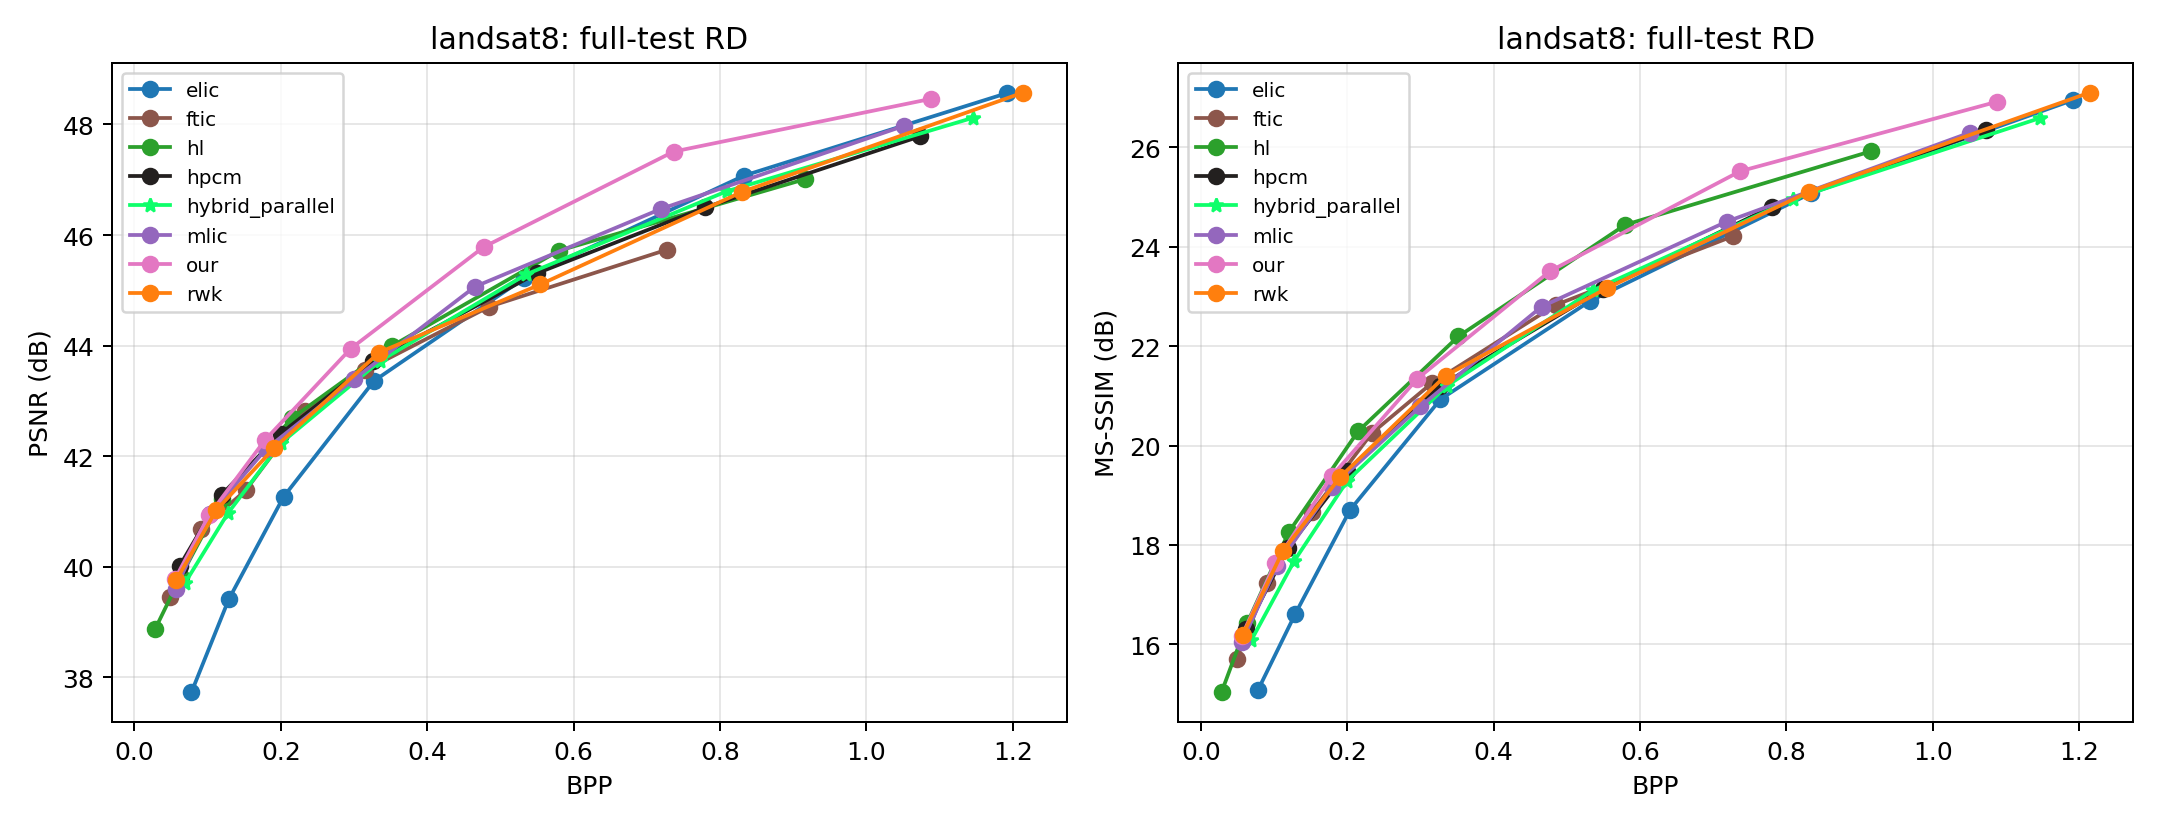

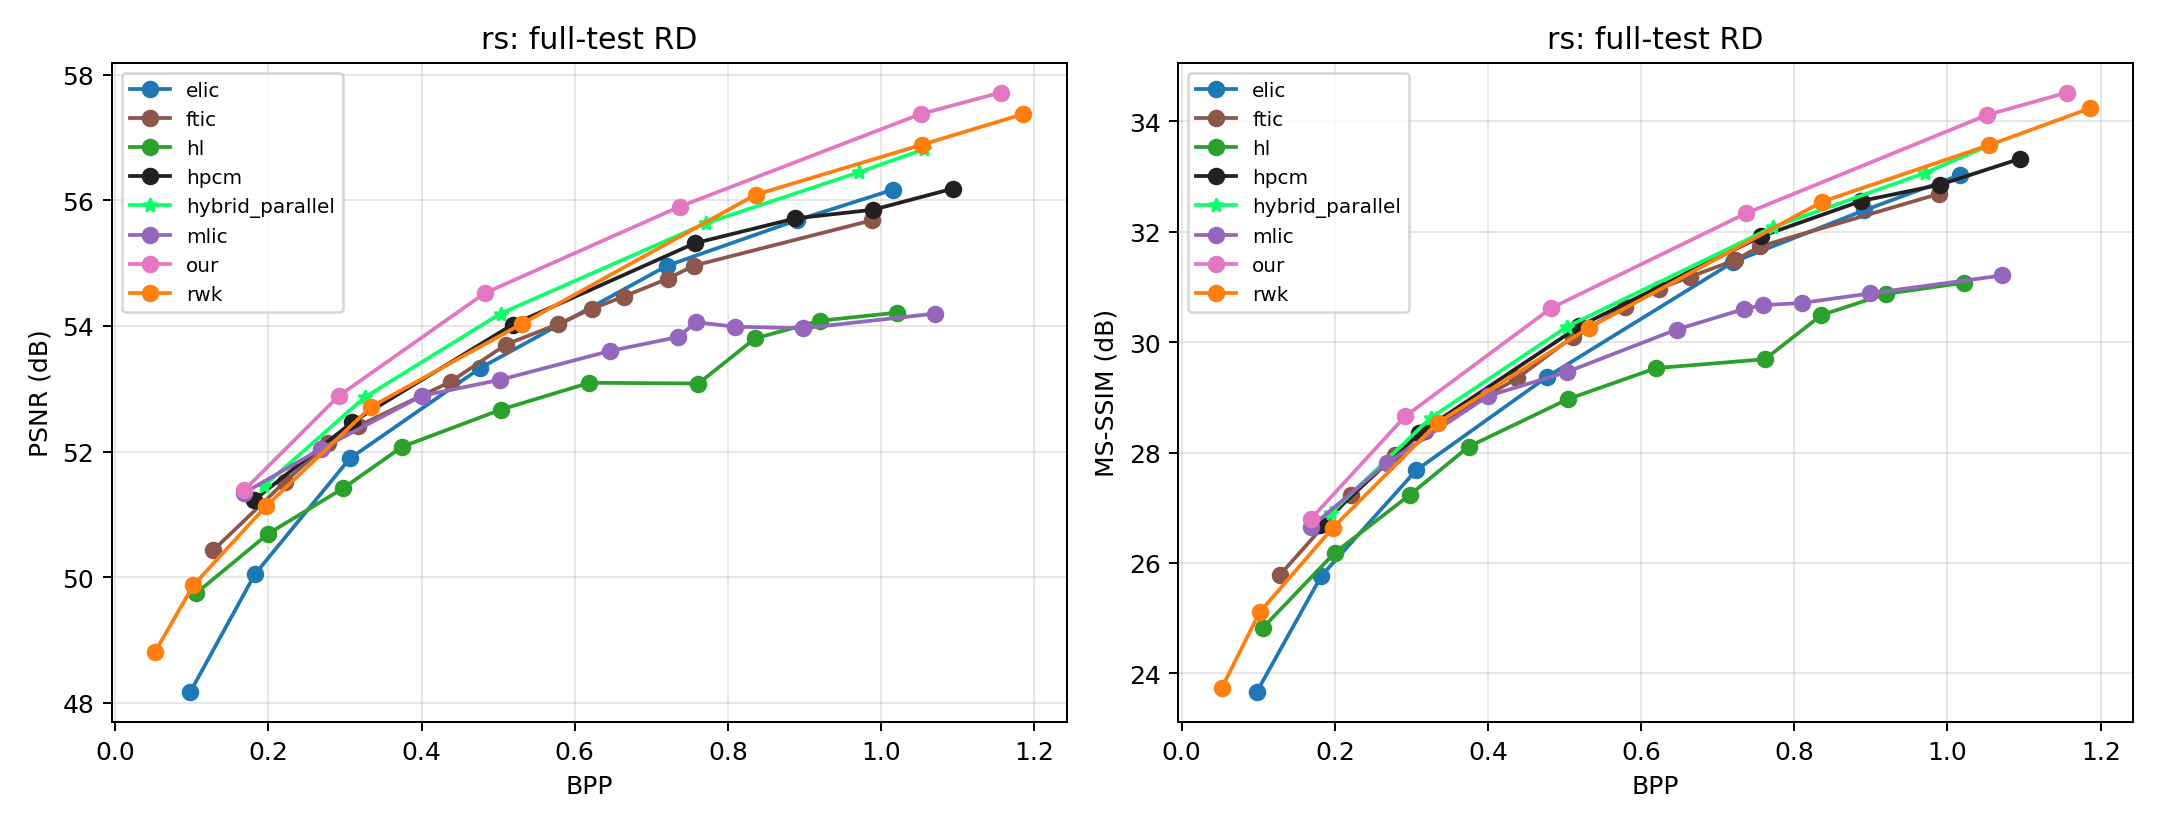

In [3]:
hybrid = rd[rd.Method.eq('hybrid_parallel')][['Dataset','Lambda','images','bpp','psnr','ms_ssim_db']]
display(hybrid.style.format({'bpp':'{:.6f}','psnr':'{:.4f}','ms_ssim_db':'{:.4f}'}))
display(Image(filename=str(CMP / 'landsat8_full_test_rd.png')))
display(Image(filename=str(CMP / 'rs_full_test_rd.png')))

## 3. Hybrid 相对其他方法的 BD-Rate

Reference 是对比方法，tested 是 hybrid；负值表示 hybrid 节省码率，正值表示 hybrid 需要更多码率。

In [4]:
cols=['dataset','reference_method','bd_rate_psnr_percent','bd_rate_ms_ssim_percent','psnr_overlap_low_db','psnr_overlap_high_db']
display(bd[cols].style.format({
 'bd_rate_psnr_percent':'{:+.2f}%', 'bd_rate_ms_ssim_percent':'{:+.2f}%',
 'psnr_overlap_low_db':'{:.2f}', 'psnr_overlap_high_db':'{:.2f}'
}))

,dataset,reference_method,bd_rate_psnr_percent,bd_rate_ms_ssim_percent,psnr_overlap_low_db,psnr_overlap_high_db
0,landsat8,elic,-13.81%,-10.39%,39.70,48.12
1,landsat8,ftic,+3.23%,+10.00%,39.70,45.73
2,landsat8,hl,+8.06%,+23.29%,39.70,47.01
3,landsat8,hpcm,+5.74%,+5.38%,40.01,47.78
4,landsat8,mlic,+8.11%,+7.23%,39.70,47.97
5,landsat8,our,+24.41%,+20.84%,39.78,48.12
6,landsat8,rwk,+3.22%,+7.21%,39.76,48.12
7,rs,elic,-17.93%,-13.45%,51.45,56.17
8,rs,ftic,-15.56%,-5.76%,51.45,55.68
9,rs,hl,-41.64%,-31.93%,51.45,54.21


## 4. 真实码流与完整编解码时间（30 图先导实验）

,dataset,label,bpp,psnr,ms_ssim_db,compress_mean_s,decompress_mean_s,stream_count,latent_exact
0,Landsat8,Original 5-group serial,0.500830,46.3412,24.1210,0.24246,0.15518,11.000000,True
1,Landsat8,"Hybrid graph, 1 entropy worker",0.554883,45.7508,23.6815,0.11307,0.12080,15.000000,True
2,Landsat8,"Hybrid graph, 4 entropy workers",0.554883,45.7508,23.6815,0.20384,0.26822,15.000000,True
3,RS,Original 5-group serial,0.773600,55.8583,32.2034,0.21481,0.13869,11.000000,True
4,RS,"Hybrid graph, 1 entropy worker",0.803630,55.5559,31.9823,0.11387,0.12175,15.000000,True
5,RS,"Hybrid graph, 4 entropy workers",0.803630,55.5559,31.9823,0.20351,0.27037,15.000000,True


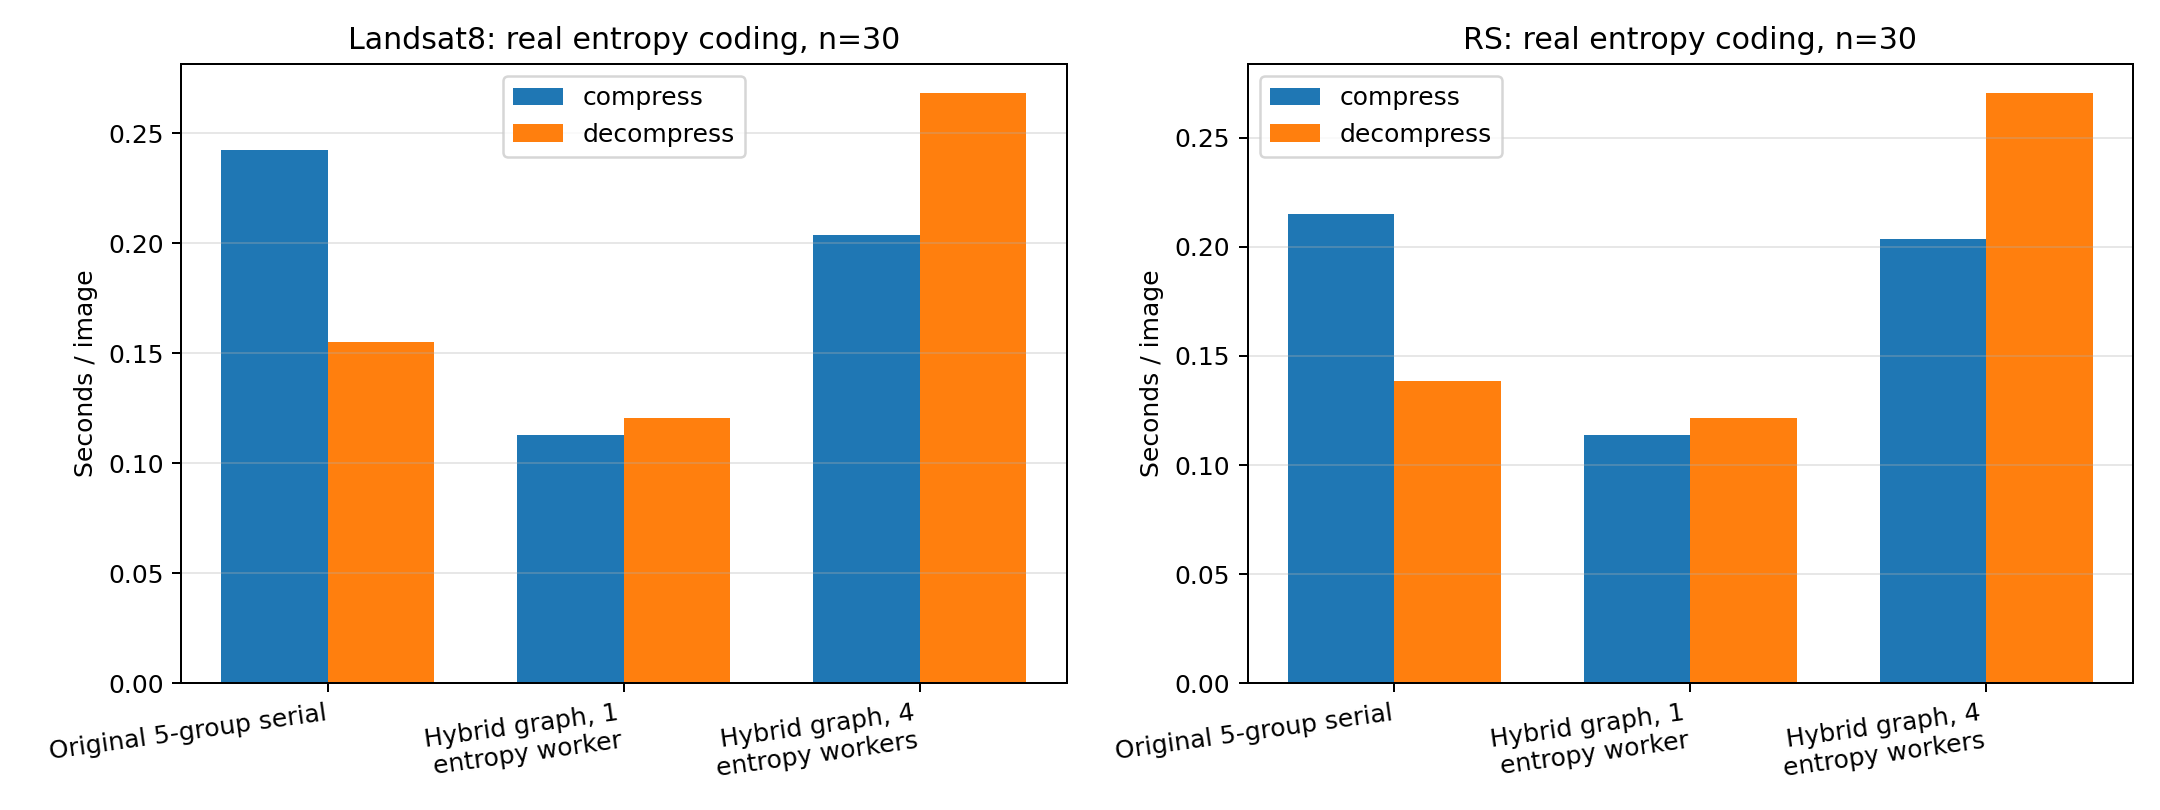

In [5]:
cols=['dataset','label','bpp','psnr','ms_ssim_db','compress_mean_s','decompress_mean_s','stream_count','latent_exact']
display(real_time[cols].style.format({
 'bpp':'{:.6f}','psnr':'{:.4f}','ms_ssim_db':'{:.4f}',
 'compress_mean_s':'{:.5f}','decompress_mean_s':'{:.5f}'
}))
display(Image(filename=str(TIME / 'real_codec_time.png')))

## 5. 数据异常点

In [6]:
display(audit)
display(Markdown('RS-ELIC 的 `52488.pth.tar` 极可能存在 λ 命名错误；正式投稿前应核对是否为 524288。RS-HL/MLIC 高码率处还有轻微 PSNR 非单调。'))

,dataset,method,previous_lambda,lambda,issues,previous_bpp,bpp,previous_psnr,psnr
0,rs,elic,52488,65536,BPP decreases; PSNR decreases; MS-SSIM decreases,1.016240,0.306333,56.171479,51.888581
1,rs,hl,262144,327680,PSNR decreases,0.619298,0.761650,53.094473,53.083055
2,rs,mlic,655360,786432,PSNR decreases,0.758588,0.809565,54.057944,53.988050
3,rs,mlic,786432,1048576,PSNR decreases,0.809565,0.898793,53.988050,53.962934


RS-ELIC 的 `52488.pth.tar` 极可能存在 λ 命名错误；正式投稿前应核对是否为 524288。RS-HL/MLIC 高码率处还有轻微 PSNR 非单调。

## 6. 当前结论

- Hybrid 在 RS 上优于多数外部方法，但相对原始 Mamba 的 PSNR BD-Rate 为约 +13.56%。
- Hybrid 在 Landsat8 上相对原始 Mamba 的 PSNR BD-Rate 为约 +24.41%，需要优先恢复压缩性能。
- 当前 Python 4-worker 熵编码比 1-worker 更慢，不能宣称真实加速。
- 下一步应补七组全串行结构消融，并改用 C++ 批量多流或持久 worker 的真实并行 coder。